In [69]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression , Lasso , LogisticRegression
from sklearn.metrics import mean_squared_error, r2_score ,f1_score,accuracy_score , mean_absolute_error,confusion_matrix,classification_report,ConfusionMatrixDisplay
from sklearn.preprocessing import PolynomialFeatures
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC,SVR
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier , RandomForestRegressor
from imblearn.over_sampling import SMOTE
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from xgboost import XGBRegressor
import tensorflow as tf
from tensorflow.keras import layers
from google.colab.patches import cv2_imshow
import cv2
from PIL import Image
import pickle
import matplotlib.image as mpimg
from sklearn.preprocessing import LabelEncoder
from sklearn.cluster import KMeans

#DOGS VS CATS Classification**

In [2]:
!pip install kaggle

In [3]:
mkdir -p ~/.kaggle && echo KGAT_cab77953dd7fb5d3a4e7317b7cb741ab > ~/.kaggle/access_token && chmod 600 ~/.kaggle/access_token

## import the data from kaggle and preprocessor

In [4]:
#kaggle api
!kaggle competitions download -c dogs-vs-cats
# downloading the data on colab environment

100% 812M/812M [00:10<00:00, 82.3MB/s]



In [5]:
!ls

dogs-vs-cats.zip  sample_data


In [6]:
# extracting the compressed data
from zipfile import ZipFile

dataset = '/content/dogs-vs-cats.zip'

with ZipFile(dataset,'r')as zip:
  zip.extractall()
  print("the data set is extracted")

the data set is extracted


In [7]:
# extract the train data
from zipfile import ZipFile

train_data = '/content/train.zip'

with ZipFile(train_data,'r')as zip:
  zip.extractall()
  print("the dataset of train is extracted")

the dataset of train is extracted


In [8]:
# counting the number of files in the train folder
import os
path, dirs, files = next(os.walk('/content/train'))
file_count = len(files)
print('Number of images: ', file_count)

Number of images:  25000


Printing the name of images

In [9]:
file_names = os.listdir('/content/train') # get the names of the fiels within the folder
print(file_names)
print(len(file_names))

['cat.2163.jpg', 'dog.10984.jpg', 'cat.2553.jpg', 'dog.2594.jpg', 'cat.3728.jpg', 'dog.4799.jpg', 'cat.7046.jpg', 'cat.8631.jpg', 'cat.1052.jpg', 'cat.11374.jpg', 'dog.4268.jpg', 'dog.4395.jpg', 'dog.593.jpg', 'dog.9465.jpg', 'cat.8061.jpg', 'dog.6919.jpg', 'cat.3473.jpg', 'dog.6165.jpg', 'cat.8334.jpg', 'dog.2982.jpg', 'cat.4524.jpg', 'dog.3206.jpg', 'dog.9264.jpg', 'dog.1591.jpg', 'cat.2720.jpg', 'cat.2668.jpg', 'cat.4673.jpg', 'cat.7340.jpg', 'cat.8332.jpg', 'cat.11524.jpg', 'cat.10078.jpg', 'dog.5686.jpg', 'cat.1774.jpg', 'dog.8489.jpg', 'cat.359.jpg', 'dog.7870.jpg', 'cat.10341.jpg', 'cat.11636.jpg', 'dog.7305.jpg', 'dog.7596.jpg', 'dog.892.jpg', 'cat.1242.jpg', 'cat.2344.jpg', 'cat.5244.jpg', 'cat.2757.jpg', 'cat.5230.jpg', 'cat.4814.jpg', 'cat.5803.jpg', 'cat.8089.jpg', 'cat.11562.jpg', 'dog.617.jpg', 'dog.10971.jpg', 'cat.3810.jpg', 'dog.11348.jpg', 'dog.5249.jpg', 'dog.8290.jpg', 'dog.6595.jpg', 'cat.6752.jpg', 'dog.6088.jpg', 'cat.8187.jpg', 'dog.2112.jpg', 'dog.4322.jpg', 'c

Display the images

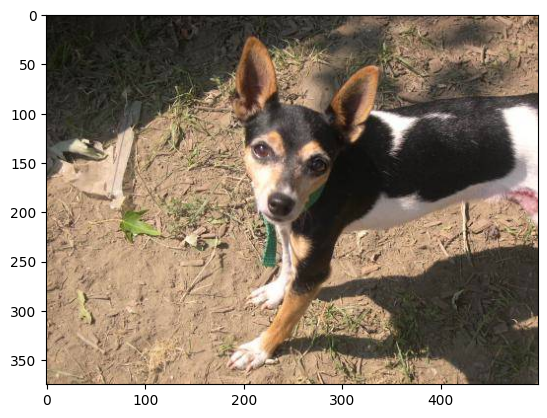

In [10]:
# display dog image
img = mpimg.imread('/content/train/dog.9872.jpg')
plt.imshow(img)
plt.show()

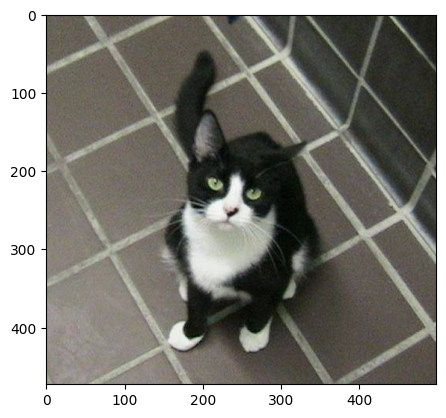

In [11]:
# display cat image
img = mpimg.imread('/content/train/cat.6349.jpg')
plt.imshow(img)
plt.show()
# images are in different sizes

In [12]:
file_names = os.listdir('/content/train')
dog_count=0
cat_count =0

for i in file_names:
  name = i[0:3]
  if name =='dog':
    dog_count +=1
  else :
    cat_count +=1
print("The number of cat images is :", cat_count)
print("The number of dog images is :", dog_count)

The number of cat images is : 12500
The number of dog images is : 12500


##Resizing all the images

In [13]:
os.mkdir('/content/resizes_train')
# make folder for resized images

In [14]:
original_folder= '/content/train/'
resized_folder = '/content/resizes_train/'

In [15]:
resized_folder = sorted(os.listdir('/content/train'))

In [16]:
len(resized_folder)

25000

In [17]:
cats = [f for f in resized_folder if f.startswith('cat')]
dogs = [f for f in resized_folder if f.startswith('dog')]

In [18]:
import os, random
N= 2000
selected = random.sample(cats, N) + random.sample(dogs, N)

In [19]:
images, labels = [], []
for f in selected:
    img = Image.open('/content/train/' + f).convert('RGB').resize((224, 224))
    images.append(np.array(img))
    labels.append(1 if f.startswith('cat') else 0)   # cat=1, dog=0

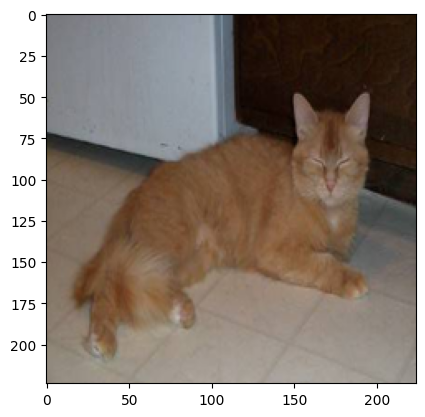

In [29]:
cat = labels.index(1)
plt.imshow(images[cat])
plt.show()

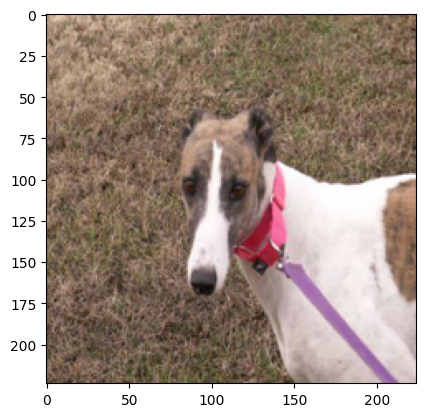

In [39]:
# display  resized dog image
img = images[2003]
plt.imshow(img)
plt.show()

In [40]:
print(labels[0:5])
print(len(labels))

[1, 1, 1, 1, 1]
4000


In [41]:
dogs =0
cats =0
for i in labels :
  if i ==0 :
    dogs +=1
  else :
     cats +=1
print("The number of dog images :", dogs)
print("The number of cat images :", cats)


The number of dog images : 2000
The number of cat images : 2000


In [42]:
values , counts = np.unique(labels , return_counts=True)
print(values)
print(counts)

[0 1]
[2000 2000]


## Split the data

In [52]:
x = np.array(images, dtype='float32')
y = np.array(labels)

In [53]:
print(x.shape)
print(y.shape)

(4000, 224, 224, 3)
(4000,)


In [54]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y)

In [55]:
print(x_test.shape,y_test.shape)

(800, 224, 224, 3) (800,)


In [56]:
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
x_train = preprocess_input(x_train)
x_test = preprocess_input(x_test)

In [57]:
print(x_train.shape, x_test.shape)

(3200, 224, 224, 3) (800, 224, 224, 3)


## Building the Neural Netowrk

In [58]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3), include_top=False, weights='imagenet')

base_model.trainable = False

model = tf.keras.Sequential([
    layers.RandomFlip('horizontal', input_shape=(224, 224, 3)),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(2, activation='softmax')
])


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [59]:
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [60]:
es = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=4,
                                      restore_best_weights=True)

In [61]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │         2,562 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,260,546 (8.62 MB)

 Trainable params: 2,562 (10.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [62]:
history1 = model.fit(x_train, y_train, epochs=15,
                     validation_split=0.2, callbacks=[es])

Epoch 1/15
80/80 ━━━━━━━━━━━━━━━━━━━━ 17s 103ms/step - accuracy: 0.8945 - loss: 0.2452 - val_accuracy: 0.9688 - val_loss: 0.0782
Epoch 2/15
80/80 ━━━━━━━━━━━━━━━━━━━━ 6s 73ms/step - accuracy: 0.9551 - loss: 0.1082 - val_accuracy: 0.9812 - val_loss: 0.0533
Epoch 3/15
80/80 ━━━━━━━━━━━━━━━━━━━━ 6s 72ms/step - accuracy: 0.9684 - loss: 0.0871 - val_accuracy: 0.9781 - val_loss: 0.0470
Epoch 4/15
80/80 ━━━━━━━━━━━━━━━━━━━━ 6s 73ms/step - accuracy: 0.9684 - loss: 0.0800 - val_accuracy: 0.9828 - val_loss: 0.0434
Epoch 5/15
80/80 ━━━━━━━━━━━━━━━━━━━━ 6s 75ms/step - accuracy: 0.9773 - loss: 0.0630 - val_accuracy: 0.9828 - val_loss: 0.0419
Epoch 6/15
80/80 ━━━━━━━━━━━━━━━━━━━━ 6s 80ms/step - accuracy: 0.9750 - loss: 0.0644 - val_accuracy: 0.9828 - val_loss: 0.0414
Epoch 7/15
80/80 ━━━━━━━━━━━━━━━━━━━━ 6s 75ms/step - accuracy: 0.9773 - loss: 0.0616 - val_accuracy: 0.9797 - val_loss: 0.0440
Epoch 8/15
80/80 ━━━━━━━━━━━━━━━━━━━━ 6s 74ms/step - accuracy: 0.9785 - loss: 0.0640 - val_accuracy: 0.9844 -

In [63]:
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False

In [64]:
model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [65]:
history2 = model.fit(x_train, y_train, epochs=10,
                     validation_split=0.2, callbacks=[es])

Epoch 1/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 18s 119ms/step - accuracy: 0.8910 - loss: 0.3046 - val_accuracy: 0.9828 - val_loss: 0.0488
Epoch 2/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 7s 91ms/step - accuracy: 0.9453 - loss: 0.1331 - val_accuracy: 0.9797 - val_loss: 0.0587
Epoch 3/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 7s 92ms/step - accuracy: 0.9633 - loss: 0.0985 - val_accuracy: 0.9812 - val_loss: 0.0562
Epoch 4/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 10s 93ms/step - accuracy: 0.9645 - loss: 0.0939 - val_accuracy: 0.9797 - val_loss: 0.0485


In [66]:
test_loss, test_acc = model.evaluate(x_test, y_test)
print(f"Test accuracy: {test_acc*100:.2f}%")

25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 59ms/step - accuracy: 0.9900 - loss: 0.0290
Test accuracy: 99.00%


In [68]:
y_pred = np.argmax(model.predict(x_test), axis=1)
print(classification_report(y_test, y_pred, target_names=['dog', 'cat'], digits=3))

25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 70ms/step
              precision    recall  f1-score   support

         dog      0.983     0.998     0.990       400
         cat      0.997     0.983     0.990       400

    accuracy                          0.990       800
   macro avg      0.990     0.990     0.990       800
weighted avg      0.990     0.990     0.990       800



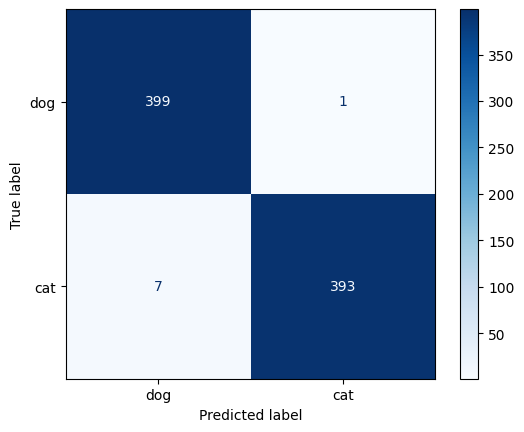

In [70]:
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=['dog', 'cat']).plot(cmap='Blues')
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()


In [71]:
model.save('dogs_vs_cats_mobilenetv2.keras')

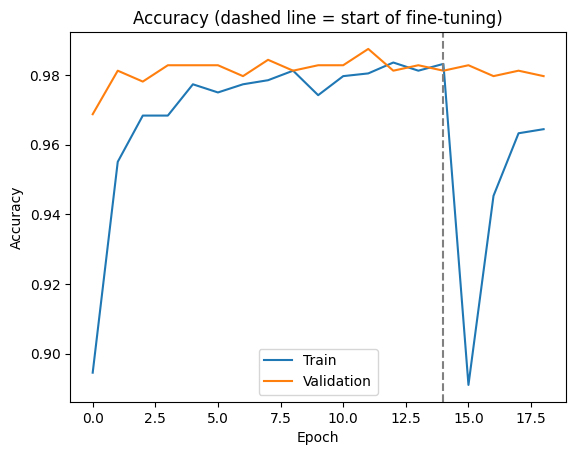

In [72]:
acc = history1.history['accuracy'] + history2.history['accuracy']
val = history1.history['val_accuracy'] + history2.history['val_accuracy']
plt.plot(acc); plt.plot(val)
plt.axvline(len(history1.history['accuracy']) - 1, color='gray', linestyle='--')
plt.title('Accuracy (dashed line = start of fine-tuning)')
plt.xlabel('Epoch'); plt.ylabel('Accuracy')
plt.legend(['Train', 'Validation'])
plt.savefig('accuracy_curve.png', dpi=150, bbox_inches='tight')
plt.show()

## predictive System

In [73]:
def predict_image(path):
    img = Image.open(path).convert('RGB').resize((224, 224))
    arr = preprocess_input(np.array(img, dtype='float32'))[None]
    p = model.predict(arr, verbose=0)[0]
    return ('Cat' if np.argmax(p) == 1 else 'Dog'), float(p.max())

print(predict_image('/content/train/dog.9872.jpg'))

('Dog', 0.9999748468399048)
